In [1]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
import keras
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)

from src.utils.ds_helper import get_dataset_distribution
from src.utils.confusion_matrix import generate_confusion
from src.utils.roc_curve import generate_roc_curve
from src.utils.training_plots import plot_train_accuracy, plot_train_loss


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC201"

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


In [18]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [20]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


In [6]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [7]:
base_model = ResNet50(weights='imagenet', 
                      include_top=False, 
                      input_shape=(224, 224, 3))

In [8]:
base_model.trainable = False

In [9]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    
    layers.Lambda(preprocess_input),
    
    base_model,
    
    layers.GlobalAveragePooling2D(),
   

    layers.Dense(
        256,
        activation='relu',
    ),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    layers.Dense(4, activation='softmax')
])

In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model.summary()


# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,308 (91.99 MB)

 Trainable params: 526,084 (2.01 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

Epoch 1/10


2026-05-23 11:14:11.558631: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


604/604 ━━━━━━━━━━━━━━━━━━━━ 449s 732ms/step - accuracy: 0.8767 - loss: 0.3541 - val_accuracy: 0.9448 - val_loss: 0.1551
Epoch 2/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 435s 719ms/step - accuracy: 0.9307 - loss: 0.2037 - val_accuracy: 0.9527 - val_loss: 0.1161
Epoch 3/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 438s 725ms/step - accuracy: 0.9440 - loss: 0.1645 - val_accuracy: 0.9671 - val_loss: 0.0907
Epoch 4/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 438s 725ms/step - accuracy: 0.9492 - loss: 0.1479 - val_accuracy: 0.9645 - val_loss: 0.0898
Epoch 5/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 229s 379ms/step - accuracy: 0.9522 - loss: 0.1362 - val_accuracy: 0.9658 - val_loss: 0.0900
Epoch 6/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 156s 259ms/step - accuracy: 0.9552 - loss: 0.1251 - val_accuracy: 0.9671 - val_loss: 0.0810
Epoch 7/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 163s 270ms/step - accuracy: 0.9577 - loss: 0.1174 - val_accuracy: 0.9750 - val_loss: 0.0645
Epoch 8/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 163s 270ms/step - accuracy: 0.9596 - loss: 0.11

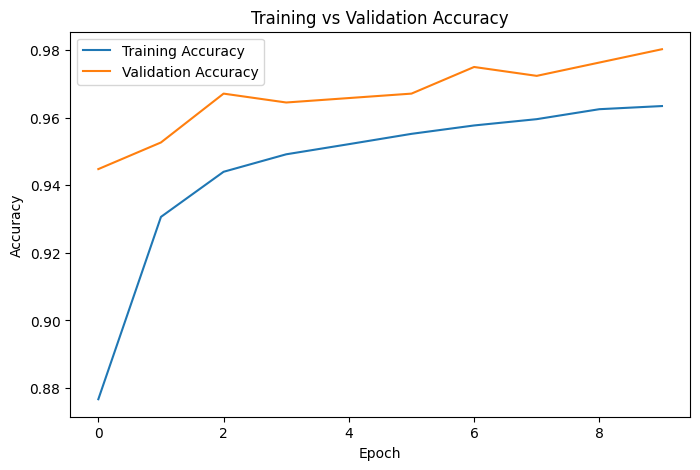

In [12]:
plot_train_accuracy(history=history)

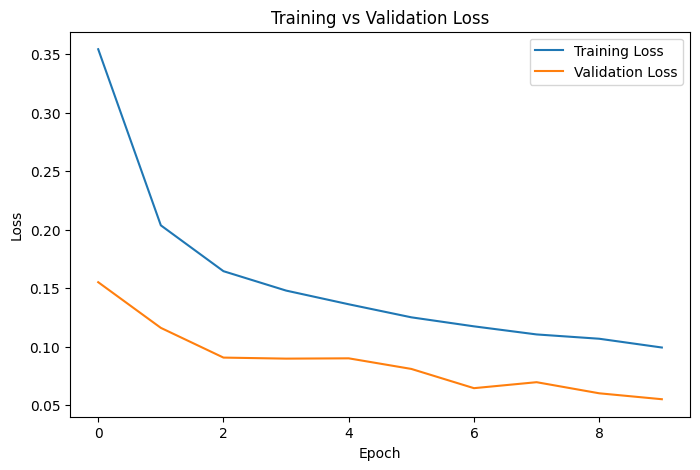

In [13]:
plot_train_loss(history=history)

In [14]:
# Save the model
model.save('CXC201.keras')
print("Model saved successfully!")

Model saved successfully!


In [4]:
model = tf.keras.models.load_model(
    os.path.join(model_path, MODEL_NAME+".keras"),
    custom_objects={"preprocess_input": preprocess_input}
)


2026-05-28 07:57:43.800598: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-05-28 07:57:43.800625: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-05-28 07:57:43.800637: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-05-28 07:57:43.800682: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-28 07:57:43.800693: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,166,478 (96.00 MB)

 Trainable params: 526,084 (2.01 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

 Optimizer params: 1,052,170 (4.01 MB)

In [22]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 18s 288ms/step - accuracy: 0.9725 - loss: 0.0721
Test Loss: 0.0721331387758255
Test Accuracy: 97.25%


In [15]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 13s 326ms/step - accuracy: 0.9803 - loss: 0.0551
Test Loss: 0.05510036274790764
Test Accuracy: 98.03%


2026-05-23 12:05:32.194435: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


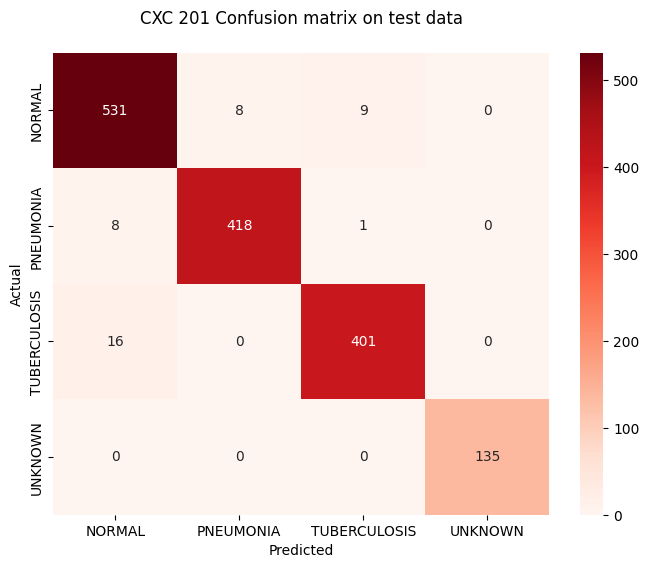

              precision    recall  f1-score   support

      NORMAL       0.96      0.97      0.96       548
   PNEUMONIA       0.98      0.98      0.98       427
TUBERCULOSIS       0.98      0.96      0.97       417
     UNKNOWN       1.00      1.00      1.00       135

    accuracy                           0.97      1527
   macro avg       0.98      0.98      0.98      1527
weighted avg       0.97      0.97      0.97      1527



In [16]:
generate_confusion(test_ds, model=model, title="CXC 201 Confusion matrix on test data")

2026-05-23 12:05:46.010960: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


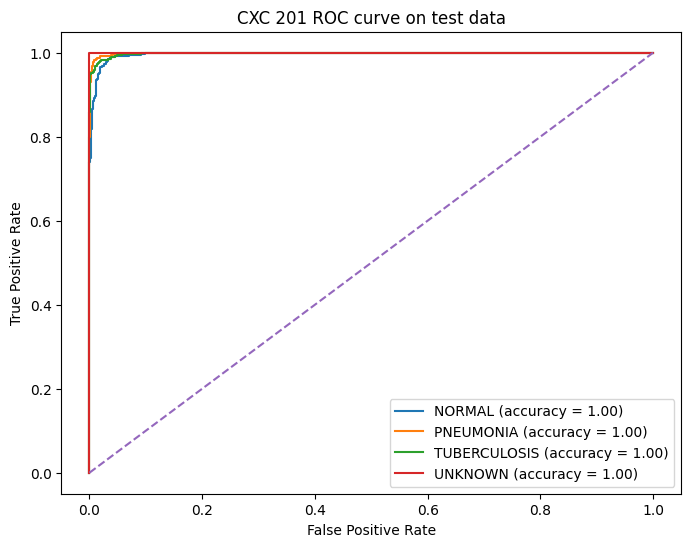

In [17]:
generate_roc_curve(test_ds, model=model, title="CXC 201 ROC curve on test data")

2026-05-23 12:05:53.595404: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


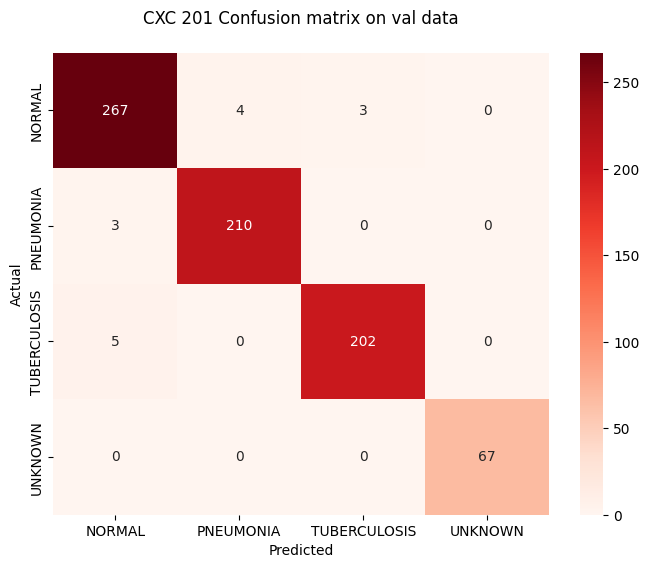

              precision    recall  f1-score   support

      NORMAL       0.97      0.97      0.97       274
   PNEUMONIA       0.98      0.99      0.98       213
TUBERCULOSIS       0.99      0.98      0.98       207
     UNKNOWN       1.00      1.00      1.00        67

    accuracy                           0.98       761
   macro avg       0.98      0.98      0.98       761
weighted avg       0.98      0.98      0.98       761



In [18]:
generate_confusion(val_ds, model=model, title="CXC 201 Confusion matrix on val data")

2026-05-23 12:06:01.065123: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


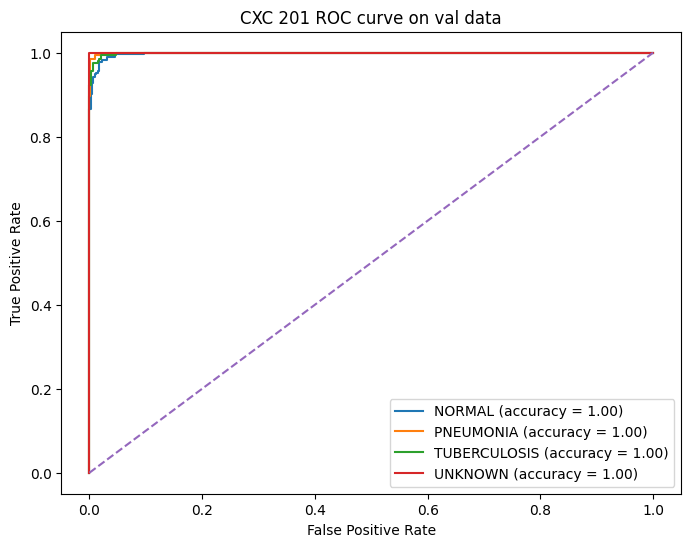

In [19]:
generate_roc_curve(val_ds, model=model, title="CXC 201 ROC curve on val data")